# 19. Extraordinary Optical Transmission (EOT) in Subwavelength Metallic Hole Arrays

## Physical Motivation & Learning Objectives
In 1998, Ebbesen et al. discovered that subwavelength hole arrays in metallic films transmit substantially more light than predicted by classical Bethe aperture theory. This **Extraordinary Optical Transmission (EOT)** is mediated by Surface Plasmon Polaritons (SPPs) and localized cavity resonances ([Liu & Lalanne, Nature 452, 728 (2008)](https://doi.org/10.1038/nature06762)).
In this tutorial:
1. We simulate a subwavelength square hole array in a gold film.
2. We identify the plasmonic EOT transmission peak.

> [!NOTE]
> **Meshing Workflow: Classic Gmsh (`examples/`)**
> Square apertures meshed via Gmsh `make_mesh_now=True`.


In [1]:
import numpy as np
import matplotlib.pyplot as plt
import concurrent.futures

from EMUstack.backend import materials, objects, plotting
from EMUstack.backend.stack import Stack



##################################################################
EMUstack is brought to you by Bjorn Sturmberg, Kokou Dossou, 
Felix Lawrence & Lindsay Botton, with support from CUDOS & ARENA
Starting EMUstack calculation ...
##################################################################



## EOT Geometry Setup: Subwavelength Au Hole Array


In [2]:
wavelengths = np.linspace(700, 1000, 6)
period = 700.0   # nm
diam1 = 266.0    # nm

light_list = [objects.Light(wl, max_order_PWs=2, theta=0.0, phi=0.0) for wl in wavelengths]

superstrate = objects.ThinFilm(period, height_nm='semi_inf', material=materials.Air, loss=False)
substrate   = objects.ThinFilm(period, height_nm='semi_inf', material=materials.Material(1.45), loss=False)

NHs = objects.NanoStruct(
    '2D_array', period, diam1, height_nm=200.0,
    inclusion_a=materials.Air, background=materials.Au, loss=True,
    inc_shape='square',
    make_mesh_now=True, lc_bkg=0.12, lc2=5.0, lc3=3.0,
    plt_msh=False
)

def simulate_stack(light):
    sim_sup = superstrate.calc_modes(light)
    sim_sub = substrate.calc_modes(light)
    sim_nhs = NHs.calc_modes(light, num_BMs=28)
    stk = Stack((sim_sub, sim_nhs, sim_sup))
    stk.calc_scat(pol='TE')
    return stk

with concurrent.futures.ThreadPoolExecutor() as executor:
    stacks_list = list(executor.map(simulate_stack, light_list))


## EOT Transmission Peak Spectrum


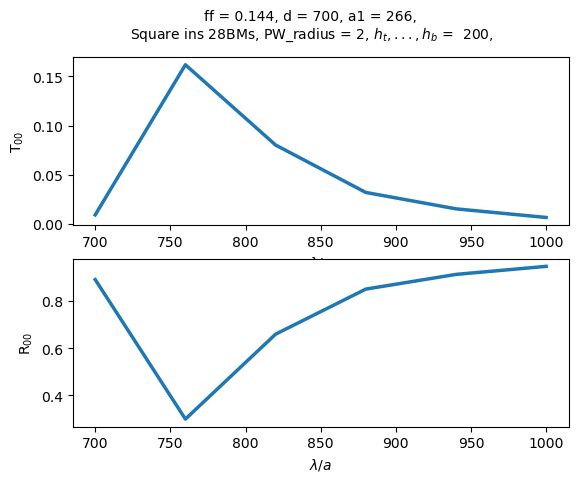

In [3]:
fig_eot = plotting.EOT_plot(stacks_list, save_pdf=False)
plt.show()


## Physical Interpretation
Resonant surface plasmon modes excited on the top and bottom metal surfaces tunnel through the subwavelength apertures, yielding strong forward transmission peaks.
